# 005. Cold-Start Behaviour

## Simplified Overview

Cold-start problems occur when you need to make predictions for new items (products, users, vulnerabilities) with little or no historical data. A recommendation system can't know a new user's preferences; an exploitation model can't observe a just-published vulnerability's real-world exploitation. Cold-start techniques fill this gap using feature similarity, aggregate patterns, and active learning.

## Technical Overview

Cold-Start Problem: Insufficient historical data prevents reliable parameter estimation for new entities.

Types:
* New Entity (e.g., new user): Zero interaction history
* New Feature (e.g., new vulnerability attribute): Never seen before
* New Context (e.g., seasonal pattern shift): Data from different distribution

Solutions leverage:
* **Content-based features**: Leverage item/user features, not interaction history
* **Popularity priors**: Default to aggregate behavior
* **Transfer learning**: Adapt parameters from similar entities
* **Active sampling**: Strategically gather labels for high-uncertainty cases

## Detailed Explanation

### The Problem Formally

Standard model:

```
P(y_i | x_i, θ_i) = Likelihood(x_i, θ_i)
```

where θ_i is entity-specific parameter estimated from n_i historical observations.

If n_i = 0 (cold-start):
* MLE for θ_i is undefined (or highly unstable)
* Posterior is dominated by prior
* Predictions collapse to priors; no personalization

### Cold-Start Taxonomy

Scenario	Example	Strategy
New Item	New vulnerability published today	Content features + global prior
New User	Customer just signed up	User features + cohort patterns
New Context	Market shift post-event	Domain adaptation; online learning
New Attribute	New data field (e.g., zero-day indicator)	Imputation; embedding transfer

### Solution Strategies

#### 1. Content-Based Features
```
θ_cold = f(x_content)
```
where x_content = [severity, attack_vector, publish_date, cwe_family, ...]

Estimate f using observed entities with θ values available.
Apply f to cold-start entities.

#### 2. Hybrid: Content + Popularity Prior
```
P(y | x_new) = λ · P_content(y | x_new) + (1-λ) · P_popular(y)
```

where P_popular(y) = aggregate distribution across all historical entities
      λ ∈ [0,1] = learned weight or fixed weight

#### 3. Transfer Learning via Embeddings
```
1. Learn entity embeddings from observed entities
   z_i = embedding(x_i, history_i)
   
2. For cold-start: z_cold = embedding(x_cold)  [use content features only]

3. Estimate θ_cold = θ(z_cold) using neighbors' θ values
   θ_cold ≈ Σ w_j · θ_j  where w_j ∝ exp(-||z_cold - z_j||²)
```
#### 4. Active Learning

Identify high-uncertainty cold-start entities → gather labels strategically
Update model → improve future cold-start predictions
Cold-Start in EPSS Context

### Scenario: New vulnerability published. EPSS must predict exploitation probability without exploitation telemetry.

Inputs available:
* CVE description (text features)
* CVSS score (severity)
* CWE (weakness category)
* Attack vector, authentication required
* Publish date
* References (vendor advisories, etc.)

Cold-start approach:
```
1. Extract content features from CVE metadata
2. Learn P(exploitation | content_features) from historical CVEs
3. Apply to new CVEs
4. As telemetry accumulates (days 1-30), update prediction via Bayesian update
5. Transition from content-based → data-driven over time
```

## Python Libraries
| Library | Purpose |
| :--- | :---: |
| `scikit-learn` | Content-based models, k-NN, PCA  |
| `pytorch` / `tensorflow` | Deep learning embeddings and transfer learning  |
| `modAL` | Active learning framework  |
| `optuna` | Hyperparameter tuning (including λ for hybrid)  |
| `imbalanced-learn` | Handle class imbalance in cold-start data |

## References
* Schein, A. I., et al. (2002). "Methods and Metrics for Cold-start Recommendations." _SIGIR_, 253-260.
* Lika, B., et al. (2014). "Facing the Cold Start Problem in Recommender Systems." _Expert Systems with Applications_, **41**(2), 1915-1920.
* Zhou, D., et al. (2008). "Learning with Local and Global Consistency." _International Conference on Machine Learning_, 321-328.

## Python Implementation Examples

### Imporation of Requisite Python Modules

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

### Example: Cold-Start Exploitation Rate Prediction for New CVEs

In [2]:
np.random.seed(42)

#### PART 1: Simulate Historical CVEs with Full Exploitation Telemetry

In [3]:
n_historical = 100
cve_ids = [f"CVE-2026-{i:05d}" for i in range(n_historical)]

# Content features: available for both historical and new CVEs
X_content = np.random.randn(n_historical, 5)  # 5 features
# Features might represent: [CVSS, has_PoC, attack_complexity, ...]
feature_names = ['CVSS_Score', 'PoC_Available', 'AttackComplexity', 'AuthRequired', 'Popularity']

# Exploitation label: known for historical CVEs
# True model: P(exploit) depends on content features
true_coeff = np.array([0.5, 0.8, -0.3, -0.4, 0.6])
true_intercept = -1.0
y_historical = (
    (X_content @ true_coeff + true_intercept + np.random.randn(n_historical) * 0.5) > 0
).astype(int)

print(f"Historical CVEs: {n_historical}")
print(f"Exploitation rate: {y_historical.mean():.2%}")

Historical CVEs: 100
Exploitation rate: 25.00%


#### PART 2: Cold-Start Scenario -- 10 New CVEs Published (No Exploitation Data Yet)

In [4]:
n_cold = 10
cve_ids_cold = [f"CVE-2026-{i:05d}" for i in range(n_historical, n_historical + n_cold)]
X_cold = np.random.randn(n_cold, 5)  # Same content features available

# True exploitation (unknown to model, but we use for evaluation)
y_cold_true = (
    (X_cold @ true_coeff + true_intercept + np.random.randn(n_cold) * 0.5) > 0
).astype(int)

print(f"\nCold-start CVEs: {n_cold}")
print(f"True exploitation (unknown to model): {y_cold_true.mean():.2%}")


Cold-start CVEs: 10
True exploitation (unknown to model): 40.00%


In [5]:
# ============================================================================
# APPROACH 1: Random Guessing (Baseline)
# ============================================================================

y_cold_random = np.full(n_cold, y_historical.mean())  # Always predict population mean
auc_random = roc_auc_score(y_cold_true, y_cold_random)
print(f"\nApproach 1 - Random (Population Mean Baseline):")
print(f"  Predictions: {y_cold_random}")
print(f"  AUC: {auc_random:.4f}")


Approach 1 - Random (Population Mean Baseline):
  Predictions: [0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25 0.25]
  AUC: 0.5000


In [6]:
# ============================================================================
# APPROACH 2: Content-Based Model (Logistic Regression on features)
# ============================================================================

# Learn relationship between content features and exploitation from historical data
scaler = StandardScaler()
X_historical_scaled = scaler.fit_transform(X_content)
X_cold_scaled = scaler.transform(X_cold)

content_model = LogisticRegression(random_state=42, max_iter=1000)
content_model.fit(X_historical_scaled, y_historical)

y_cold_content_proba = content_model.predict_proba(X_cold_scaled)[:, 1]
y_cold_content = (y_cold_content_proba >= 0.5).astype(int)
auc_content = roc_auc_score(y_cold_true, y_cold_content_proba)

print(f"\nApproach 2 - Content-Based (Logistic Regression):")
print(f"  Predictions (probabilities): {y_cold_content_proba}")
print(f"  AUC: {auc_content:.4f}")


Approach 2 - Content-Based (Logistic Regression):
  Predictions (probabilities): [8.46836537e-03 8.92857423e-01 9.27038493e-01 6.87806709e-02
 1.29935713e-01 2.82528728e-02 1.29910860e-01 2.72293681e-02
 8.65106397e-01 4.04754476e-04]
  AUC: 1.0000


In [7]:
# ============================================================================
# APPROACH 3: Hybrid (Content + Popularity Prior)
# ============================================================================

# Combine content-based predictions with population mean
lambda_hybrid = 0.7  # Weight for content-based (tune this)
y_cold_hybrid_proba = (
    lambda_hybrid * y_cold_content_proba +
    (1 - lambda_hybrid) * y_historical.mean()
)
y_cold_hybrid = (y_cold_hybrid_proba >= 0.5).astype(int)
auc_hybrid = roc_auc_score(y_cold_true, y_cold_hybrid_proba)

print(f"\nApproach 3 - Hybrid (λ={lambda_hybrid}):")
print(f"  Predictions (probabilities): {y_cold_hybrid_proba}")
print(f"  AUC: {auc_hybrid:.4f}")


Approach 3 - Hybrid (λ=0.7):
  Predictions (probabilities): [0.08092786 0.7000002  0.72392695 0.12314647 0.165955   0.09477701
 0.1659376  0.09406056 0.68057448 0.07528333]
  AUC: 1.0000


In [8]:
# ============================================================================
# APPROACH 4: Transfer Learning via Nearest Neighbors
# ============================================================================

# Learn low-dimensional embeddings from historical CVEs
n_components = 3
pca = PCA(n_components=n_components)
Z_historical = pca.fit_transform(X_historical_scaled)
Z_cold = pca.transform(X_cold_scaled)

# For each cold-start CVE, find k nearest historical neighbors
k_neighbors = 5
nn = NearestNeighbors(n_neighbors=k_neighbors)
nn.fit(Z_historical)

distances, indices = nn.kneighbors(Z_cold)

# Estimate exploitation probability as weighted average of neighbors
y_cold_nn_proba = np.zeros(n_cold)
for i in range(n_cold):
    # Weight by inverse distance (closer neighbors have more influence)
    weights = 1.0 / (distances[i] + 1e-6)  # Avoid division by zero
    weights /= weights.sum()
    
    # Weighted average of neighbors' exploitation labels
    neighbor_labels = y_historical[indices[i]]
    y_cold_nn_proba[i] = (weights * neighbor_labels).sum()

y_cold_nn = (y_cold_nn_proba >= 0.5).astype(int)
auc_nn = roc_auc_score(y_cold_true, y_cold_nn_proba)

print(f"\nApproach 4 - Transfer Learning (k-NN, k={k_neighbors}):")
print(f"  Predictions (probabilities): {y_cold_nn_proba}")
print(f"  AUC: {auc_nn:.4f}")


Approach 4 - Transfer Learning (k-NN, k=5):
  Predictions (probabilities): [0.16817929 0.20773141 1.         0.59503628 0.5877758  0.15813436
 0.24206833 0.17592583 0.8208224  0.19171888]
  AUC: 0.8750


In [9]:
# ============================================================================
# APPROACH 5: Warm-Starting—Simulating Online Updates
# ============================================================================

# Simulate scenario: As new CVE exploitation data arrives (days 1-7),
# update predictions progressively

# Assume we get labels for 2 cold-start CVEs after day 3
n_labeled_cold = 2
X_warmstart = np.vstack([X_historical_scaled, X_cold_scaled[:n_labeled_cold]])
y_warmstart = np.hstack([y_historical, y_cold_true[:n_labeled_cold]])

# Retrain model with combined historical + labeled cold data
content_model_warmed = LogisticRegression(random_state=42, max_iter=1000)
content_model_warmed.fit(X_warmstart, y_warmstart)

# Predict remaining cold-start CVEs
y_cold_warmed_proba = content_model_warmed.predict_proba(X_cold_scaled[n_labeled_cold:])[:, 1]
auc_warmed = roc_auc_score(y_cold_true[n_labeled_cold:], y_cold_warmed_proba)

print(f"\nApproach 5 - Warm-Starting (after labeling {n_labeled_cold} cold CVEs):")
print(f"  Predictions (remaining cold CVEs): {y_cold_warmed_proba}")
print(f"  AUC (on unlabeled cold CVEs): {auc_warmed:.4f}")



Approach 5 - Warm-Starting (after labeling 2 cold CVEs):
  Predictions (remaining cold CVEs): [9.34703850e-01 6.76739474e-02 1.23890665e-01 2.84576429e-02
 1.20846572e-01 2.53451570e-02 8.67818233e-01 4.07324726e-04]
  AUC (on unlabeled cold CVEs): 1.0000



Performance comparison visualized


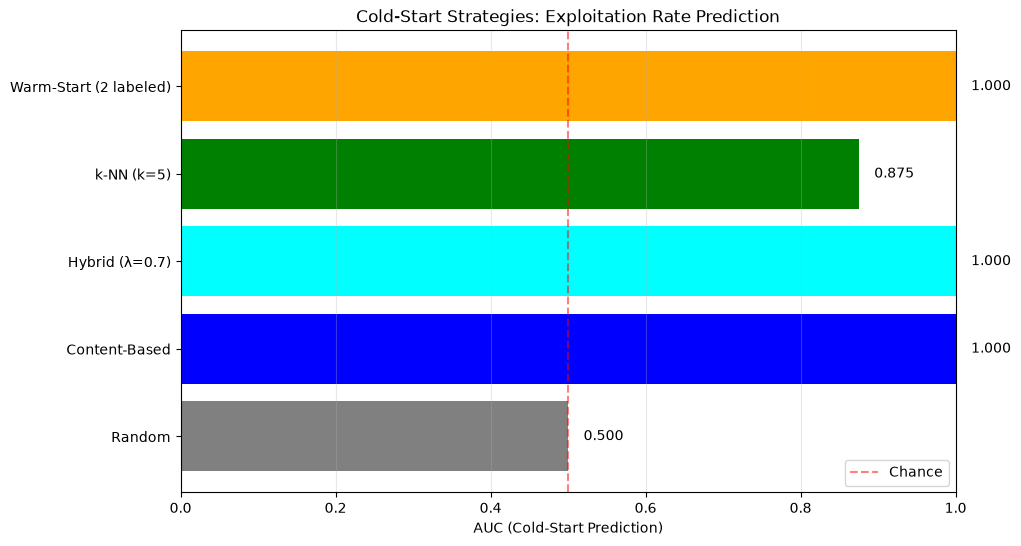

In [10]:
# ============================================================================
# Comparison and Visualization
# ============================================================================

results = {
    'Random': auc_random,
    'Content-Based': auc_content,
    f'Hybrid (λ={lambda_hybrid})': auc_hybrid,
    f'k-NN (k={k_neighbors})': auc_nn,
    f'Warm-Start ({n_labeled_cold} labeled)': auc_warmed
}

fig, ax = plt.subplots(figsize=(10, 6))
approaches = list(results.keys())
aucs = list(results.values())

bars = ax.barh(approaches, aucs, color=['gray', 'blue', 'cyan', 'green', 'orange'])
ax.set_xlabel('AUC (Cold-Start Prediction)')
ax.set_title('Cold-Start Strategies: Exploitation Rate Prediction')
ax.set_xlim([0, 1])

# Add value labels
for i, (approach, auc) in enumerate(results.items()):
    ax.text(auc + 0.02, i, f'{auc:.3f}', va='center')

ax.axvline(0.5, color='red', linestyle='--', alpha=0.5, label='Chance')
ax.legend()
ax.grid(True, alpha=0.3, axis='x')

print("\nPerformance comparison visualized")

In [11]:
# ============================================================================
# Active Learning: Prioritize labeling high-uncertainty CVEs
# ============================================================================

# Uncertainty = entropy of prediction
entropy_cold = -np.sum([
    y_cold_content_proba * np.log(y_cold_content_proba + 1e-10),
    (1 - y_cold_content_proba) * np.log(1 - y_cold_content_proba + 1e-10)
], axis=0)

# Rank by uncertainty
uncertainty_ranking = np.argsort(-entropy_cold)

print(f"\nActive Learning: CVEs ranked by prediction uncertainty (high → low):")
for rank, idx in enumerate(uncertainty_ranking[:5], 1):
    print(f"  {rank}. CVE-2026-{n_historical + idx:05d} (uncertainty: {entropy_cold[idx]:.4f})")

print("\n(Label high-uncertainty CVEs first to improve model fastest)")


Active Learning: CVEs ranked by prediction uncertainty (high → low):
  1. CVE-2026-00108 (uncertainty: 0.3956)
  2. CVE-2026-00104 (uncertainty: 0.3863)
  3. CVE-2026-00106 (uncertainty: 0.3862)
  4. CVE-2026-00101 (uncertainty: 0.3405)
  5. CVE-2026-00102 (uncertainty: 0.2612)

(Label high-uncertainty CVEs first to improve model fastest)
